# Feature Extraction from PLAID Waveforms
### Appliance Identification from Voltage and Current Waveforms
**EC5203 Machine Learning · Group 6 – Team Plug Detectives**

**Goal:** turn each of the 1,810 cleaned recordings (`clean_index.csv`) into one row of 15 physically meaningful
features, saved as `features.csv`.

**Approach:**
1. Clean each waveform in memory (`prepare`): rescale voltage to 120 V RMS, find the switch-on,
   cut 20 aligned steady-state cycles, and flag surge or spike problems. The raw CSV files are never changed.
2. Compute four feature groups: power (5), waveform shape (5), V-I trajectory (3) and transient (2).
3. Test every group on a **fake signal with known answers** before using real data.

| Group | Features |
|---|---|
| Power | I RMS, real power P, reactive power Q, power factor, phase shift |
| Shape | crest factor, THD, H3/H1, H5/H1, half-cycle asymmetry |
| V-I | loop area, voltage at current peak, V-I curvature |
| Transient | inrush ratio, settling time |

Metadata columns (`type`, `location`, `collection_time`, `status`) are kept in `features.csv` **only** as the label,
the split group and for error analysis. They are never used as model inputs.

In [16]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
try:
    from tqdm.auto import tqdm
except ImportError:
    tqdm = lambda x: x

DATA = Path.home() / "Documents" / "10084619"
WAVES = DATA / "submetered_new"

FS = 30_000          # samples per second
F0 = 60              # mains frequency (Hz)
SPC = FS // F0       # samples per cycle = 500
N_CYC = 20           # cycles in the steady-state window

clean = pd.read_csv(DATA / "clean_index.csv")
print(clean.shape)
print(clean["type"].value_counts())

(1810, 28)
type
Hairdryer                   246
Compact Fluorescent Lamp    230
Fan                         220
Air Conditioner             204
Laptop                      202
Microwave                   200
Incandescent Light Bulb     157
Fridge                      108
Heater                       85
Vacuum                       83
Washing Machine              75
Name: count, dtype: int64


## 2. Load and inspect one recording

`load_wave(rec_id)` reads one CSV (column 0 = current in A, column 1 = voltage in V; no header)
and returns two NumPy arrays. We plot one recording (incandescent bulb, id 50):
the whole recording, to see the switch-on, and a 3-cycle zoom, to see the wave shapes.

samples: 60000 | length: 2.0 s
current: -7.37 to 3.04 A
voltage: -189.7 to 184.8 V


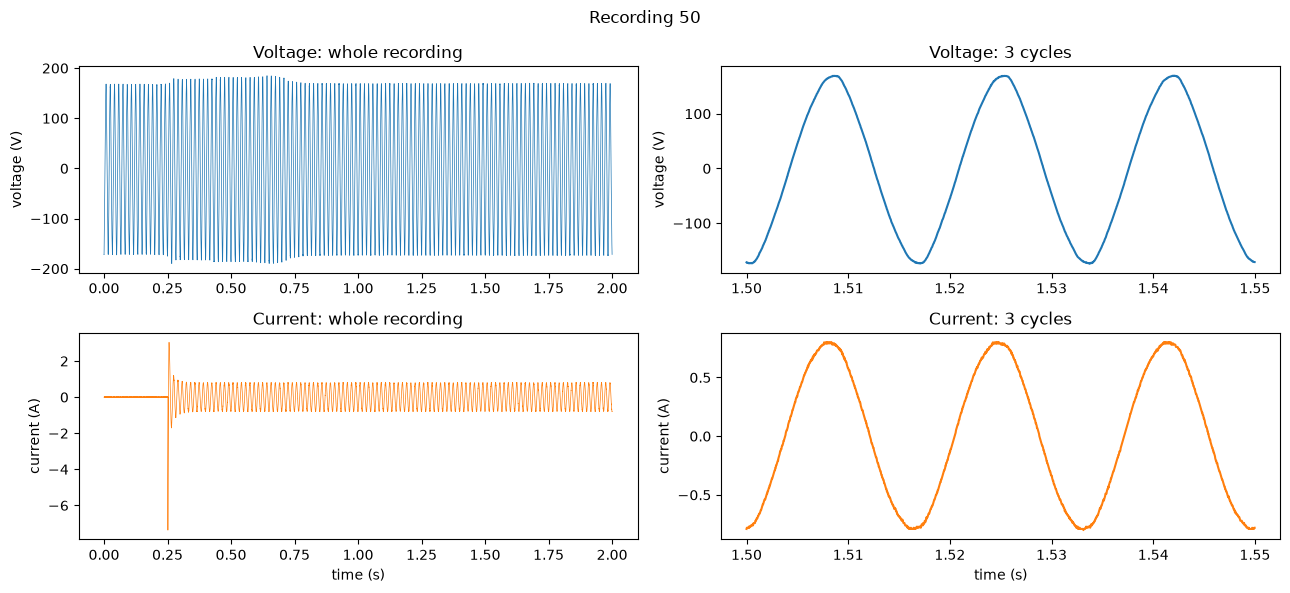

In [17]:
def load_wave(rec_id):
    """Read one recording and return (current, voltage) as NumPy arrays."""
    w = pd.read_csv(WAVES / f"{rec_id}.csv", header=None, names=["current", "voltage"])
    return w["current"].to_numpy(), w["voltage"].to_numpy()

rec_id = 50                                    # an incandescent light bulb
i, v = load_wave(rec_id)
t = np.arange(len(i)) / FS                     # time of every sample, in seconds

print("samples:", len(i), "| length:", len(i) / FS, "s")
print(f"current: {i.min():.2f} to {i.max():.2f} A")
print(f"voltage: {v.min():.1f} to {v.max():.1f} V")

zoom = (t >= 1.5) & (t < 1.5 + 3 / F0)         # 3 cycles starting at 1.5 s
fig, axes = plt.subplots(2, 2, figsize=(13, 6))
axes[0, 0].plot(t, v, lw=0.5)
axes[1, 0].plot(t, i, lw=0.5, color="tab:orange")
axes[0, 1].plot(t[zoom], v[zoom])
axes[1, 1].plot(t[zoom], i[zoom], color="tab:orange")
axes[0, 0].set_title("Voltage: whole recording"); axes[0, 1].set_title("Voltage: 3 cycles")
axes[1, 0].set_title("Current: whole recording"); axes[1, 1].set_title("Current: 3 cycles")
for ax in axes[0]: ax.set_ylabel("voltage (V)")
for ax in axes[1]: ax.set_ylabel("current (A)"); ax.set_xlabel("time (s)")
fig.suptitle(f"Recording {rec_id}")
plt.tight_layout(); plt.show()

## 3. Split the signal into cycles

- `rising_crossings(v)`: sample positions where the voltage crosses zero going up (one per cycle).
  Crossings closer than 0.8 cycle (400 samples) are noise and are skipped.
- `cycle_rms(i)`: RMS current of every full cycle (one value per 500 samples).
  This shows off → switch-on surge → steady state as a simple curve.

id 50: 2.0 s -> raw crossings 120, kept 120
id 123: 3.0 s -> raw crossings 283, kept 180
first 3 crossings: [ 109  609 1109] | gaps: [500 500]
cycles: 120 | cycle RMS, cycles 13-20: [0.005 0.005 1.995 0.875 0.691 0.623 0.592 0.577]


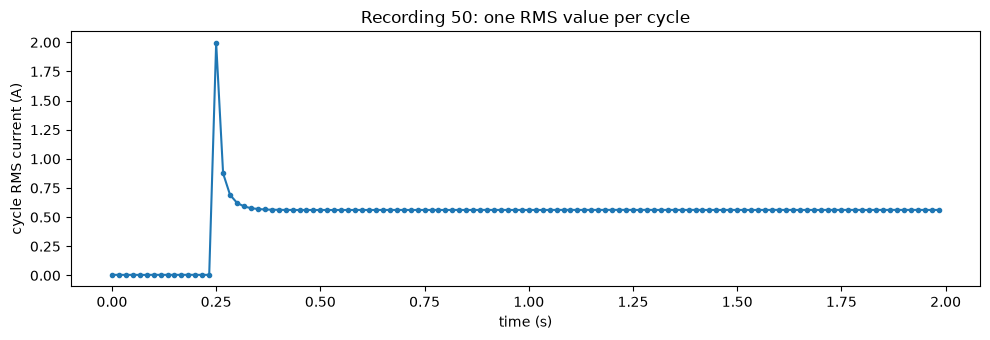

In [18]:
def rising_crossings(v, min_gap=int(0.8 * SPC)):
    """Sample positions where the voltage crosses zero going up: one per cycle.
    Crossings closer than 0.8 cycle are noise and are skipped."""
    idx = np.flatnonzero((v[:-1] < 0) & (v[1:] >= 0))      # every upward crossing, noise included
    keep = []
    for k in idx:
        if not keep or k - keep[-1] >= min_gap:              # first one, or far enough from the last kept
            keep.append(k)
    return np.array(keep)

def cycle_rms(i):
    """RMS current of each full cycle: one number per 500 samples."""
    n = len(i) // SPC                                        # number of full cycles
    return np.sqrt((i[:n * SPC].reshape(n, SPC) ** 2).mean(axis=1))

# Why the 0.8-cycle rule? Compare raw vs cleaned crossings on two recordings
for rid in [50, 123]:
    _, vv = load_wave(rid)
    raw = np.flatnonzero((vv[:-1] < 0) & (vv[1:] >= 0))
    print(f"id {rid}: {len(vv) / FS:.1f} s -> raw crossings {len(raw)}, kept {len(rising_crossings(vv))}")

# One RMS value per cycle for the bulb (id 50, loaded in Step 2)
r = rising_crossings(v)
rms = cycle_rms(i)
print("first 3 crossings:", r[:3], "| gaps:", np.diff(r[:3]))
print("cycles:", len(rms), "| cycle RMS, cycles 13-20:", rms[13:21].round(3))

plt.figure(figsize=(10, 3.5))
plt.plot(np.arange(len(rms)) / F0, rms, marker=".")
plt.xlabel("time (s)"); plt.ylabel("cycle RMS current (A)")
plt.title(f"Recording {rec_id}: one RMS value per cycle")
plt.tight_layout(); plt.show()

## 4. Find the steady state (stable-segment method)

A cycle is **steady** when the appliance is ON (cycle RMS > 0.03 A) and its RMS barely changes:
the coefficient of variation (CV = std ÷ mean) over 10 neighbouring cycles is below 2%.

- `stable_segments(i)`: all runs of steady cycles at least 20 cycles long.
- `steady_window_start(i, v)`: the last 20 aligned cycles of the **longest** run
  (None if there is no steady run, e.g. a laptop whose load keeps changing).

In the plots: green = stable runs, red = the chosen 20-cycle window.

id 50: stable runs: 0.40-1.93 s | window starts: 1.59 s
id 1293: stable runs: 0.37-2.55 s, 2.82-3.93 s | window starts: 2.20 s
id 22: stable runs: none | window starts: none (fall back to last 20 cycles)


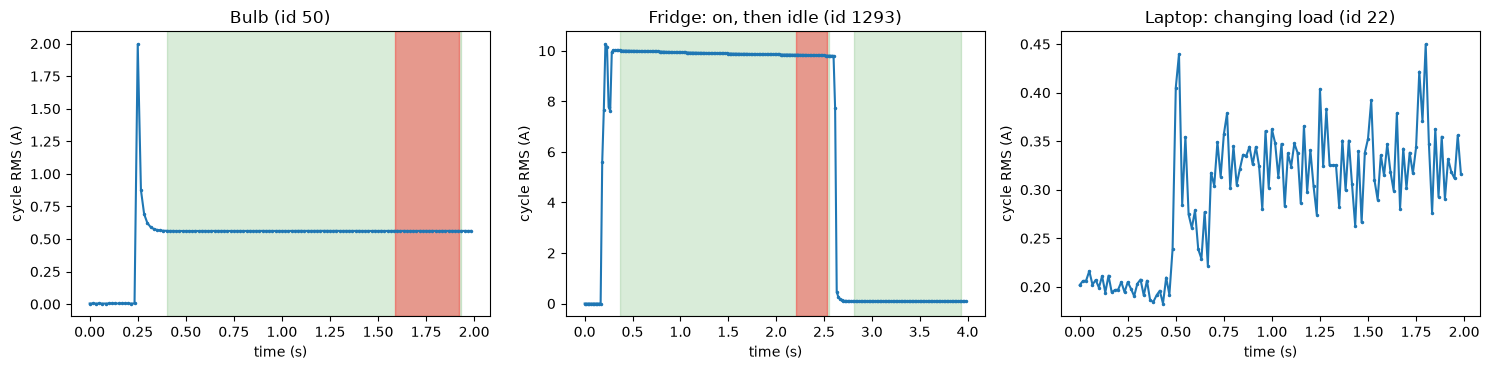

In [19]:
def stable_segments(i, win=10, tol=0.02, min_on=0.03, min_len=N_CYC):
    """Runs of cycles where the appliance is ON and its cycle RMS is steady.
    Returns a list of (first_cycle, end_cycle) pairs; end_cycle is not included."""
    rms = pd.Series(cycle_rms(i))
    cv = rms.rolling(win, center=True).std() / rms.rolling(win, center=True).mean()
    stable = ((cv < tol) & (rms > min_on)).to_numpy().astype(int)
    edges = np.diff(np.r_[0, stable, 0])                       # +1 where a run starts, -1 where it ends
    starts, ends = np.flatnonzero(edges == 1), np.flatnonzero(edges == -1)
    return [(a, b) for a, b in zip(starts, ends) if b - a >= min_len]

def steady_window_start(i, v, n_cycles=N_CYC):
    """Start sample of the last 20 aligned cycles in the longest stable run (None if none)."""
    segs = stable_segments(i)
    if not segs:
        return None
    a, b = max(segs, key=lambda s: s[1] - s[0])                # longest run
    r = rising_crossings(v)
    ok = r[(r >= a * SPC) & (r + n_cycles * SPC <= b * SPC)]    # crossings with 20 cycles of room
    return ok[-1] if len(ok) else None

# Try it on three different kinds of recording
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
for ax, (rid, name) in zip(axes, [(50, "Bulb"), (1293, "Fridge: on, then idle"),
                                  (22, "Laptop: changing load")]):
    ii, vv = load_wave(rid)
    rms = cycle_rms(ii)
    segs = stable_segments(ii)
    start = steady_window_start(ii, vv)
    ax.plot(np.arange(len(rms)) / F0, rms, marker=".", ms=3)
    for a, b in segs:                                           # green = every stable run
        ax.axvspan(a / F0, b / F0, color="green", alpha=0.15)
    if start is not None:                                       # red = the chosen 20-cycle window
        ax.axvspan(start / FS, (start + N_CYC * SPC) / FS, color="red", alpha=0.35)
    ax.set_title(f"{name} (id {rid})"); ax.set_xlabel("time (s)"); ax.set_ylabel("cycle RMS (A)")
    runs = ", ".join(f"{a / F0:.2f}-{b / F0:.2f} s" for a, b in segs) or "none"
    win = "none (fall back to last 20 cycles)" if start is None else f"{start / FS:.2f} s"
    print(f"id {rid}: stable runs: {runs} | window starts: {win}")
plt.tight_layout(); plt.show()

## 5. Prepare a recording: `prepare()`

For one recording, in memory (the raw CSV is never modified):

1. **Rescale voltage to 120 V RMS**, which removes the batch voltage differences found in the EDA.
2. **Choose the 20-cycle window** from the longest stable run (Step 4); if there is none, use the last 20 cycles.
3. **Find the switch-on**: the first cycle above 50% of the window's steady current (None = already on).
4. **Set quality flags:**
   - `stable_found`: a steady run was found (False → fallback window).
   - `window_ok`: the window starts ≥ 0.5 s after switch-on (no surge inside).
   - `spike_in_window`: a voltage spike > 200 V inside the window.

`fake_signal()` builds a made-up recording with known answers, to test `prepare()`.

In [20]:
def prepare(i, v, n_cycles=N_CYC, settle_s=0.5):
    """Clean one recording in memory and cut its 20-cycle steady-state window."""
    v = v * 120 / np.sqrt(np.mean(v ** 2))                     # 1. rescale voltage to 120 V RMS
    r = rising_crossings(v)
    start = steady_window_start(i, v, n_cycles)                # 2. window from the longest stable run
    stable_found = start is not None
    if start is None:                                          #    no stable run: use the last 20 cycles
        start = r[r + n_cycles * SPC <= len(v)][-1]
    end = start + n_cycles * SPC
    level = np.sqrt(np.mean(i[start:end] ** 2))                # 3. steady current in the window
    above = np.flatnonzero(cycle_rms(i) > 0.5 * level)
    onset = above[0] * SPC if len(above) and above[0] > 0 else None   # switch-on sample (None = already on)
    earliest = onset + int(settle_s * FS) if onset is not None else 0
    return {"i": i, "v": v,                                    # 4. everything later steps need
            "i_win": i[start:end], "v_win": v[start:end],
            "onset": onset, "start": start,
            "stable_found": stable_found,                      #    quality flags
            "window_ok": start >= earliest,
            "spike_in_window": np.abs(v[start:end]).max() > 200}

def prepare_recording(rec_id, **kw):
    return prepare(*load_wave(rec_id), **kw)

def fake_signal(seconds=2.0, i_rms=10.0, lag_deg=30.0, on_at=0.5, inrush=1.0):
    """A made-up recording where we KNOW the right answers (for testing)."""
    t = np.arange(int(seconds * FS)) / FS
    v = 120 * np.sqrt(2) * np.sin(2 * np.pi * F0 * t)
    i = i_rms * np.sqrt(2) * np.sin(2 * np.pi * F0 * t - np.radians(lag_deg))
    surge = 1 + (inrush - 1) * np.exp(-(t - on_at) / 0.05)    # extra current that fades in ~0.05 s
    return np.where(t >= on_at, i * surge, 0.0), v           # zero before switch-on

def summary(name, p):
    """One row describing what prepare() decided."""
    return {"recording": name,
            "onset_s": None if p["onset"] is None else round(p["onset"] / FS, 2),
            "window_s": f"{p['start'] / FS:.2f}-{(p['start'] + N_CYC * SPC) / FS:.2f}",
            "window_rms_A": round(float(np.sqrt(np.mean(p["i_win"] ** 2))), 3),
            "v_rms_V": round(float(np.sqrt(np.mean(p["v"] ** 2))), 1),
            "stable_found": p["stable_found"], "window_ok": p["window_ok"],
            "spike_in_window": p["spike_in_window"]}

types = clean.set_index("id")["type"]
rows = [summary("fake (10 A, 3x surge at 0.5 s)", prepare(*fake_signal(inrush=3.0)))]
for rid in [50, 1293, 22, 6, 1746, 52]:
    rows.append(summary(f"{types[rid]} {rid}", prepare_recording(rid)))
display(pd.DataFrame(rows))

,recording,onset_s,window_s,window_rms_A,v_rms_V,stable_found,window_ok,spike_in_window
0,"fake (10 A, 3x surge at 0.5 s)",0.50,1.60-1.93,10.000,120.0,True,True,False
1,Incandescent Light Bulb 50,0.25,1.59-1.92,0.562,120.0,True,True,False
2,Fridge 1293,0.18,2.20-2.54,9.827,120.0,True,True,False
3,Laptop 22,NaN,1.66-1.99,0.340,120.0,False,True,False
4,Fridge 6,NaN,9.59-9.92,0.970,120.0,True,True,False
5,Fridge 1746,0.20,0.36-0.69,3.882,120.0,False,False,False
6,Incandescent Light Bulb 52,0.28,1.59-1.92,0.562,120.0,True,True,False


## 6. Group 1: power features (7)

Computed from the 20-cycle steady window (`i_win`, `v_win`):

| Feature | Formula | Meaning |
|---|---|---|
| `i_rms` | √mean(i²) | Effective current (A) |
| `i_peak` | max\|i\| | Highest current in the window (A) |
| `p_w` | mean(v·i) | Real power: energy actually used (W) |
| `q_var` | √(S² − P²) | Non-active power: current that does no useful work (var) |
| `pf` | P ÷ S, with S = V_rms·I_rms | Power factor: share of the current doing useful work |
| `phase_deg` | angle(I₁) − angle(V₁) | Timing of the 60 Hz current vs the voltage (+ = leads, − = lags) |
| `dpf` | cos(phase) | Power factor from timing alone (ignores pulse shape) |

Tested first on a fake signal with known answers (10 A, current 30° behind the voltage).

In [21]:
def power_features(i_win, v_win):
    """Group 1: 7 power features from the 20-cycle steady window."""
    i_rms = np.sqrt(np.mean(i_win ** 2))                      # effective current (A)
    v_rms = np.sqrt(np.mean(v_win ** 2))                      # effective voltage (V), 120 after rescaling
    P = np.mean(v_win * i_win)                                # real power (W): average of v × i
    S = v_rms * i_rms                                         # apparent power (VA)
    PF = P / S if S > 0 else np.nan                           # power factor
    Q = np.sqrt(max(S ** 2 - P ** 2, 0.0))                    # non-active power (var)
    I1 = np.fft.rfft(i_win)[N_CYC]                            # 60 Hz part of the current (bin 20)
    V1 = np.fft.rfft(v_win)[N_CYC]                            # 60 Hz part of the voltage
    phase = np.degrees(np.angle(I1 * np.conj(V1)))            # current angle minus voltage angle
    return {"i_rms": i_rms, "i_peak": np.abs(i_win).max(), "p_w": P, "q_var": Q,
            "pf": PF, "dpf": np.cos(np.radians(phase)), "phase_deg": phase}

# Test 1: fake signal (10 A, current 30° behind the voltage) → answers we can calculate by hand
p = prepare(*fake_signal(i_rms=10, lag_deg=30))
print("fake:", {k: round(float(x), 3) for k, x in power_features(p["i_win"], p["v_win"]).items()})

# Test 2: one real recording of several types
rows = []
for t in ["Heater", "Incandescent Light Bulb", "Fridge", "Compact Fluorescent Lamp", "Laptop", "Fan"]:
    rid = clean.loc[clean["type"] == t, "id"].iloc[0]
    p = prepare_recording(rid)
    rows.append({"type": t, "id": rid, **power_features(p["i_win"], p["v_win"])})
display(pd.DataFrame(rows).round(3))

fake: {'i_rms': 10.0, 'i_peak': 14.142, 'p_w': 1039.23, 'q_var': 600.0, 'pf': 0.866, 'dpf': 0.866, 'phase_deg': -30.0}


,type,id,i_rms,i_peak,p_w,q_var,pf,dpf,phase_deg
0,Heater,123,11.966,16.81,1396.908,115.141,0.997,0.999,3.116
1,Incandescent Light Bulb,50,0.562,0.81,65.683,10.917,0.986,0.987,9.308
2,Fridge,6,0.970,1.43,115.099,17.573,0.989,0.998,4.020
3,Compact Fluorescent Lamp,1,0.351,1.13,23.887,34.683,0.567,0.807,36.184
4,Laptop,22,0.340,1.82,19.886,34.219,0.502,0.952,17.893
5,Fan,56,0.263,0.38,29.172,12.056,0.924,0.925,22.287


## 7. Group 2a: shape features (6)

Numbers that describe the **shape** of the current in the 20-cycle window (sine vs pulses):

| Feature | Formula | Pure sine | Pulses |
|---|---|---|---|
| `crest_factor` | peak ÷ RMS | 1.414 | high (3–5+) |
| `form_factor` | RMS ÷ mean\|i\| | 1.111 | high |
| `skewness` | mean(z³) | 0 | 0 if both halves mirror |
| `kurtosis` | mean(z⁴) − 3 | −1.5 | high (positive) |
| `conduction_angle` | share of samples where \|i\| > max(5% of peak, 0.03 A) | ≈ 0.97 | low |
| `cycle_stability` | mean correlation of each cycle with the average cycle | 1.0 | lower if the shape changes |

(z = (i − mean) ÷ std, the standardised current.)

In [22]:
def shape_features(i_win, on_frac=0.05, min_amp=0.03):
    """Group 2a: 6 numbers describing the SHAPE of the current wave."""
    peak = np.abs(i_win).max()
    rms = np.sqrt(np.mean(i_win ** 2))
    z = (i_win - i_win.mean()) / i_win.std()                 # standardised current
    cycles = i_win.reshape(N_CYC, SPC)                       # 20 rows, one per cycle
    avg = cycles.mean(axis=0)                                # the average cycle
    return {"crest_factor": peak / rms,
            "form_factor": rms / np.mean(np.abs(i_win)),
            "skewness": np.mean(z ** 3),
            "kurtosis": np.mean(z ** 4) - 3,
            "conduction_angle": np.mean(np.abs(i_win) > max(on_frac * peak, min_amp)),
            "cycle_stability": np.mean([np.corrcoef(c, avg)[0, 1] for c in cycles])}

# Test 1: a pure sine → the textbook values
p = prepare(*fake_signal(i_rms=10, lag_deg=0))
print("fake sine:", {k: round(float(x), 3) for k, x in shape_features(p["i_win"]).items()})

# Test 2: real recordings: smooth loads vs pulsed loads
rows = []
for rid in [123, 50, 56, 6, 1, 22, 27]:
    p = prepare_recording(rid)
    rows.append({"type": types[rid], "id": rid, **shape_features(p["i_win"])})
display(pd.DataFrame(rows).round(3))

fake sine: {'crest_factor': 1.414, 'form_factor': 1.111, 'skewness': 0.0, 'kurtosis': -1.5, 'conduction_angle': 0.972, 'cycle_stability': 1.0}


,type,id,crest_factor,form_factor,skewness,kurtosis,conduction_angle,cycle_stability
0,Heater,123,1.405,1.117,0.004,-1.495,0.969,1.000
1,Incandescent Light Bulb,50,1.441,1.111,-0.000,-1.496,0.966,1.000
2,Fan,56,1.443,1.107,-0.005,-1.535,0.939,1.000
3,Fridge,6,1.474,1.078,0.021,-1.582,0.983,1.000
4,Compact Fluorescent Lamp,1,3.221,1.629,0.004,1.823,0.674,0.999
5,Laptop,22,5.354,2.019,-0.095,8.147,0.214,0.953
6,Microwave,27,2.137,1.287,0.025,-0.095,0.955,0.999


## 8. Group 2b: harmonic features (8)

The FFT splits the 20-cycle window into frequencies. Bin spacing = 30,000 ÷ 10,000 samples = 3 Hz,
so harmonic *n* (n × 60 Hz) sits in bin 20·n.

| Feature | Formula | Meaning |
|---|---|---|
| `thd` | √(H2² + … + H40²) ÷ H1 | Total harmonic distortion: how far from a pure sine |
| `h2_h1` … `h9_h1` | Hn ÷ H1 (n = 2, 3, 5, 7, 9) | Size of each harmonic relative to the 60 Hz part |
| `hf_noise_ratio` | √(energy above 2.4 kHz ÷ total energy) | High-frequency content (e.g. electronics switching) |
| `half_cycle_asym` | \|mean(i)\| ÷ mean(\|i\|) | Difference between the positive and negative halves (0 = mirror images) |

pure sine                  {'thd': 0.0, 'h2_h1': 0.0, 'h3_h1': 0.0, 'h5_h1': 0.0, 'h7_h1': 0.0, 'h9_h1': 0.0, 'hf_noise_ratio': 0.0, 'half_cycle_asym': 0.0}
sine + 30% 3rd + 10% 5th   {'thd': 0.316, 'h2_h1': 0.0, 'h3_h1': 0.3, 'h5_h1': 0.1, 'h7_h1': 0.0, 'h9_h1': 0.0, 'hf_noise_ratio': 0.0, 'half_cycle_asym': 0.0}


,type,id,thd,h2_h1,h3_h1,h5_h1,h7_h1,h9_h1,hf_noise_ratio,half_cycle_asym
0,Heater,123,0.042,0.002,0.012,0.027,0.004,0.018,0.010,0.000
1,Incandescent Light Bulb,50,0.015,0.000,0.013,0.007,0.002,0.003,0.008,0.007
2,Fan,56,0.035,0.004,0.029,0.017,0.005,0.003,0.017,0.015
3,Fridge,6,0.147,0.017,0.076,0.099,0.068,0.030,0.008,0.004
4,Compact Fluorescent Lamp,1,0.967,0.003,0.770,0.401,0.212,0.165,0.095,0.016
5,Laptop,22,1.426,0.007,0.931,0.732,0.502,0.321,0.023,0.028
6,Microwave,27,0.542,0.033,0.484,0.234,0.043,0.032,0.003,0.000
7,Air Conditioner,9,0.025,0.001,0.023,0.009,0.004,0.003,0.004,0.003


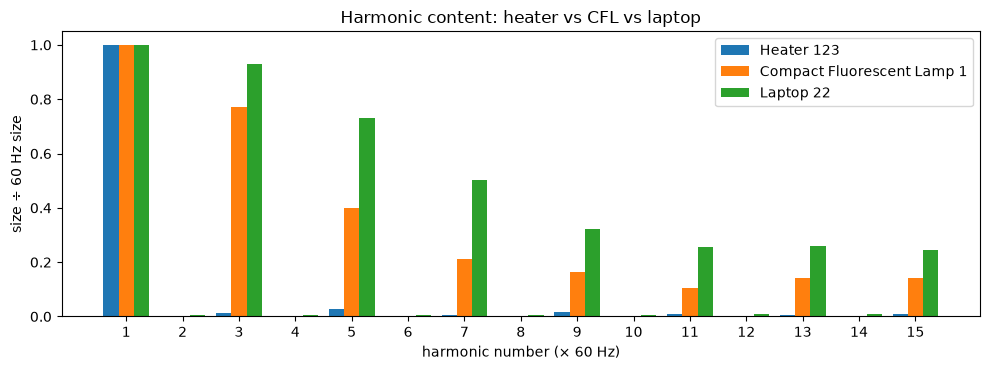

In [23]:
def harmonic_features(i_win, n_max=40, hf_hz=2400):
    """Group 2b: 8 numbers from the frequency content of the current."""
    X = np.abs(np.fft.rfft(i_win))                   # size of each frequency (bin k = k × 3 Hz)
    h = X[N_CYC::N_CYC][:n_max]                      # harmonics 1..40 = bins 20, 40, 60, ...
    hf_bin = int(hf_hz * len(i_win) / FS)            # bin of 2.4 kHz = 800
    return {"thd": np.sqrt(np.sum(h[1:] ** 2)) / h[0],
            "h2_h1": h[1] / h[0], "h3_h1": h[2] / h[0], "h5_h1": h[4] / h[0],
            "h7_h1": h[6] / h[0], "h9_h1": h[8] / h[0],
            "hf_noise_ratio": np.sqrt(np.sum(X[hf_bin + 1:] ** 2) / np.sum(X[1:] ** 2)),
            "half_cycle_asym": abs(np.mean(i_win)) / np.mean(np.abs(i_win))}

# Test 1: signals where we KNOW the harmonics
t = np.arange(2 * FS) / FS
w = 2 * np.pi * F0 * t
v_test = 120 * np.sqrt(2) * np.sin(w)
for name, i_test in [("pure sine", np.sin(w)),
                     ("sine + 30% 3rd + 10% 5th", np.sin(w) + 0.3 * np.sin(3 * w) + 0.1 * np.sin(5 * w))]:
    p = prepare(i_test, v_test)
    print(f"{name:26s}", {k: round(float(x), 3) for k, x in harmonic_features(p["i_win"]).items()})

# Test 2: real recordings
rows = []
for rid in [123, 50, 56, 6, 1, 22, 27, 9]:
    p = prepare_recording(rid)
    rows.append({"type": types[rid], "id": rid, **harmonic_features(p["i_win"])})
display(pd.DataFrame(rows).round(3))

# Picture: harmonics 1-15 for three appliances
fig, ax = plt.subplots(figsize=(10, 3.8))
for rid, off in [(123, -0.27), (1, 0), (22, 0.27)]:
    X = np.abs(np.fft.rfft(prepare_recording(rid)["i_win"]))
    h = X[N_CYC::N_CYC][:15]
    ax.bar(np.arange(1, 16) + off, h / h[0], width=0.27, label=f"{types[rid]} {rid}")
ax.set_xticks(range(1, 16)); ax.set_xlabel("harmonic number (× 60 Hz)"); ax.set_ylabel("size ÷ 60 Hz size")
ax.set_title("Harmonic content: heater vs CFL vs laptop"); ax.legend()
plt.tight_layout(); plt.show()

## 9. Group 3: V-I trajectory features (5)

Plot current against voltage over one cycle (the **average** of the 20 window cycles, to reduce noise),
both divided by their peaks so the loop fits in a −1…1 box (shape, not size).

| Feature | How it's measured | Line (resistor) | Ellipse (phase φ) | Z-shape (CFL) |
|---|---|---|---|---|
| `vi_area` | Loop area (shoelace formula) | 0 | π·sin φ | medium |
| `vi_width0` | Spread of current where voltage ≈ 0 | ≈ 0 | ≈ 2·sin φ | ≈ 0 |
| `vi_mid_slope` | Slope of current vs voltage where \|v\| < 0.3 | 1 | ≈ cos φ | ≈ 0 |
| `vi_curvature` | End slope (\|v\| > 0.7) ÷ middle slope (NaN if middle slope < 0.3) | 1 | 1 | NaN |
| `v_at_ipeak` | Voltage (÷ peak) at the moment of the current peak | 1 | cos φ | < 1 |

fake lag  0°: {'vi_area': 0.0, 'vi_width0': 0.075, 'vi_mid_slope': 1.0, 'vi_curvature': 1.0, 'v_at_ipeak': 1.0}
fake lag 30°: {'vi_area': 1.571, 'vi_width0': 1.065, 'vi_mid_slope': 0.866, 'vi_curvature': 1.0, 'v_at_ipeak': 0.864}


,type,id,vi_area,vi_width0,vi_mid_slope,vi_curvature,v_at_ipeak
0,Heater,123,0.163,0.168,0.835,1.254,0.922
1,Incandescent Light Bulb,50,0.487,0.406,1.071,0.941,0.953
2,Fan,56,1.186,0.860,0.906,1.064,0.899
3,Air Conditioner,9,0.546,0.443,0.977,0.998,0.981
4,Fridge,6,0.201,0.171,1.720,0.547,0.975
5,Vacuum,45,0.076,0.126,0.419,2.033,0.995
6,Compact Fluorescent Lamp,1,0.581,0.094,-0.009,NaN,0.712
7,Laptop,22,0.251,0.085,-0.013,NaN,0.936
8,Microwave,27,1.686,1.961,0.443,0.479,0.099


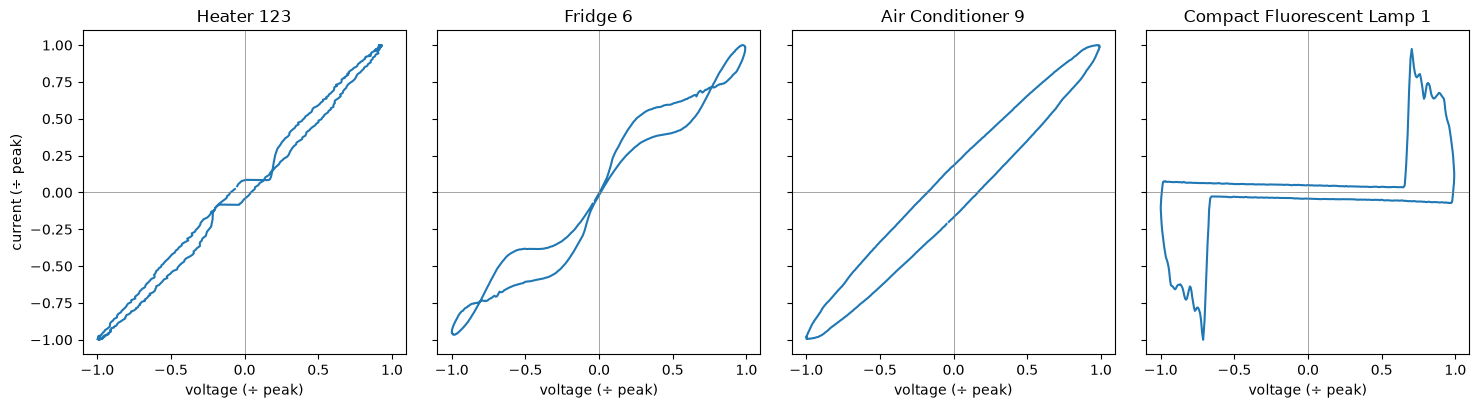

In [24]:
def vi_features(i_win, v_win):
    """Group 3: 5 numbers describing the V-I loop of the average cycle."""
    i_c = i_win.reshape(N_CYC, SPC).mean(axis=0)             # average current cycle
    v_c = v_win.reshape(N_CYC, SPC).mean(axis=0)             # average voltage cycle
    i_n, v_n = i_c / np.abs(i_c).max(), v_c / np.abs(v_c).max()   # scale both to −1…1
    area = 0.5 * abs(np.sum(v_n * np.roll(i_n, -1) - np.roll(v_n, -1) * i_n))   # shoelace formula
    near0 = np.abs(v_n) < 0.05                               # points where voltage ≈ 0
    mid, end = np.abs(v_n) < 0.3, np.abs(v_n) > 0.7          # middle part and end parts of the loop
    s_mid = np.polyfit(v_n[mid], i_n[mid], 1)[0]             # slope in the middle
    s_end = np.polyfit(v_n[end], i_n[end], 1)[0]             # slope near the voltage peaks
    return {"vi_area": area,
                        "vi_width0": np.ptp(i_n[near0]) if near0.any() else np.nan,
            "vi_mid_slope": s_mid,
            "vi_curvature": s_end / s_mid if abs(s_mid) > 0.3 else np.nan,
            "v_at_ipeak": abs(v_n[np.argmax(np.abs(i_n))])}

# Test 1: fake signals with known answers
for lag in [0, 30]:
    p = prepare(*fake_signal(i_rms=10, lag_deg=lag))
    print(f"fake lag {lag:2d}°:", {k: round(float(x), 3) for k, x in vi_features(p["i_win"], p["v_win"]).items()})

# Test 2: real recordings
rows = []
for rid in [123, 50, 56, 9, 6, 45, 1, 22, 27]:
    p = prepare_recording(rid)
    rows.append({"type": types[rid], "id": rid, **vi_features(p["i_win"], p["v_win"])})
display(pd.DataFrame(rows).round(3))

# Picture: four loop shapes
fig, axes = plt.subplots(1, 4, figsize=(15, 3.8), sharex=True, sharey=True)
for ax, rid in zip(axes, [123, 6, 9, 1]):
    p = prepare_recording(rid)
    i_c = p["i_win"].reshape(N_CYC, SPC).mean(axis=0)
    v_c = p["v_win"].reshape(N_CYC, SPC).mean(axis=0)
    ax.plot(v_c / np.abs(v_c).max(), i_c / np.abs(i_c).max())
    ax.axhline(0, color="grey", lw=0.5); ax.axvline(0, color="grey", lw=0.5)
    ax.set_title(f"{types[rid]} {rid}"); ax.set_xlabel("voltage (÷ peak)"); ax.set_aspect("equal")
axes[0].set_ylabel("current (÷ peak)")
plt.tight_layout(); plt.show()

## 10. Group 4: transient (switch-on) features (4)

Measured between the switch-on and the start of the steady window, relative to the steady current
(so big and small appliances are comparable). **NaN if no switch-on was recorded** (the appliance was already on).

| Feature | Meaning |
|---|---|
| `inrush_ratio` | Highest current after switch-on ÷ highest current in the steady window |
| `settling_time` | Seconds until the cycle RMS stays within ±5% of the steady RMS |
| `transient_energy` | Extra current during settling, in "seconds of full steady current" |
| `inrush_duration` | Seconds the cycle RMS stays above 1.5 × the steady RMS |

In [25]:
def transient_features(p, tol=0.05, high=1.5):
    """Group 4: 4 numbers describing the switch-on surge (NaN if no switch-on was recorded)."""
    nan = {"inrush_ratio": np.nan, "settling_time": np.nan,
           "transient_energy": np.nan, "inrush_duration": np.nan}
    if p["onset"] is None:                                    # already on: the surge was never recorded
        return nan
    i, i_win = p["i"], p["i_win"]
    level = np.sqrt(np.mean(i_win ** 2))                      # steady RMS current
    on, st = p["onset"] // SPC, p["start"] // SPC             # switch-on and window start, in cycles
    rel = cycle_rms(i)[on:st] / level                         # each cycle ÷ steady (1.0 = steady)
    outside = np.flatnonzero(np.abs(rel - 1) > tol)           # cycles more than ±5% from steady
    settle = outside[-1] + 1 if len(outside) else 0           # cycles until it stays within ±5%
    return {"inrush_ratio": np.abs(i[p["onset"]:]).max() / np.abs(i_win).max(),
            "settling_time": settle / F0,
            "transient_energy": np.clip(rel[:settle] - 1, 0, None).sum() / F0,
            "inrush_duration": np.sum(rel > high) / F0}

# Test 1: fake signals with and without a surge
for name, sig in [("fake, no surge", fake_signal(inrush=1.0)), ("fake, 3x surge", fake_signal(inrush=3.0))]:
    print(f"{name:16s}", {k: round(float(x), 3) for k, x in transient_features(prepare(*sig)).items()})

# Test 2: real recordings, including the two hard pairs
rows = []
for rid in [50, 56, 9, 123, 7, 45, 1293, 1, 22, 6]:
    p = prepare_recording(rid)
    rows.append({"type": types[rid], "id": rid, **transient_features(p)})
display(pd.DataFrame(rows).round(3))

fake, no surge   {'inrush_ratio': 1.0, 'settling_time': 0.0, 'transient_energy': 0.0, 'inrush_duration': 0.0}
fake, 3x surge   {'inrush_ratio': 2.791, 'settling_time': 0.183, 'transient_energy': 0.095, 'inrush_duration': 0.067}


,type,id,inrush_ratio,settling_time,transient_energy,inrush_duration
0,Incandescent Light Bulb,50,9.099,0.083,0.058,0.033
1,Fan,56,1.211,0.017,0.002,0.000
2,Air Conditioner,9,1.423,2.283,0.551,0.000
3,Heater,123,1.048,0.017,0.000,0.000
4,Hairdryer,7,1.206,0.350,0.038,0.000
5,Vacuum,45,4.517,0.817,0.565,0.300
6,Fridge,1293,1.046,0.100,0.001,0.000
7,Compact Fluorescent Lamp,1,NaN,NaN,NaN,NaN
8,Laptop,22,NaN,NaN,NaN,NaN
9,Fridge,6,NaN,NaN,NaN,NaN


## 11. All features together: `extract_features()`

`extract_features(i, v)` = `prepare()` + the five feature groups, giving one dictionary of
**30 candidate features** and **3 quality flags** (`stable_found`, `window_ok`, `spike_in_window`).
The flags are **not** model features; they are kept for quality checks.

The same function is used for training (all recordings) and for predicting a new recording.

Checks before the full run: there are exactly 30 features, one recording of each of the 11 types works,
NaN appear only where expected (no switch-on; Z-shaped V-I loops), and there are no infinite values.

In [26]:
def extract_features(i, v):
    """Raw current + voltage → 30 candidate features + 3 quality flags (one dictionary)."""
    p = prepare(i, v)
    feats = {}
    feats.update(power_features(p["i_win"], p["v_win"]))      # Group 1:  7
    feats.update(shape_features(p["i_win"]))                  # Group 2a: 6
    feats.update(harmonic_features(p["i_win"]))               # Group 2b: 8
    feats.update(vi_features(p["i_win"], p["v_win"]))         # Group 3:  5
    feats.update(transient_features(p))                       # Group 4:  4
    feats.update({"stable_found": p["stable_found"],          # quality flags (NOT features)
                  "window_ok": p["window_ok"],
                  "spike_in_window": p["spike_in_window"]})
    return feats

def extract_features_recording(rec_id):
    return extract_features(*load_wave(rec_id))

FLAGS = ["stable_found", "window_ok", "spike_in_window"]

# Check 1: exactly 30 features
f = extract_features_recording(50)
TIMES = ["onset_s", "window_start_s"]
feature_cols = [k for k in f if k not in FLAGS + TIMES]
print(len(feature_cols), "features:", feature_cols)

# Check 2: one recording of every type
one_each = clean.groupby("type")["id"].first()
rows = [{"type": t, "id": rid, **extract_features_recording(rid)} for t, rid in one_each.items()]
check = pd.DataFrame(rows).set_index("type")
display(check[["id", "i_rms", "pf", "thd", "crest_factor", "vi_area", "inrush_ratio"] + FLAGS].round(3))

# Check 3: NaN only where expected, and no infinite values
nan_counts = check[feature_cols].isna().sum()
print("NaN per feature:\n", nan_counts[nan_counts > 0])
print("Infinite values:", int(np.isinf(check[feature_cols].astype(float)).sum().sum()))
print("Table shape:", check.shape)

30 features: ['i_rms', 'i_peak', 'p_w', 'q_var', 'pf', 'dpf', 'phase_deg', 'crest_factor', 'form_factor', 'skewness', 'kurtosis', 'conduction_angle', 'cycle_stability', 'thd', 'h2_h1', 'h3_h1', 'h5_h1', 'h7_h1', 'h9_h1', 'hf_noise_ratio', 'half_cycle_asym', 'vi_area', 'vi_width0', 'vi_mid_slope', 'vi_curvature', 'v_at_ipeak', 'inrush_ratio', 'settling_time', 'transient_energy', 'inrush_duration']


,id,i_rms,pf,thd,crest_factor,vi_area,inrush_ratio,stable_found,window_ok,spike_in_window
type,,,,,,,,,,
Air Conditioner,9,1.218,0.985,0.025,1.437,0.546,1.423,True,True,False
Compact Fluorescent Lamp,1,0.351,0.567,0.967,3.221,0.581,NaN,True,True,False
Fan,56,0.263,0.924,0.035,1.443,1.186,1.211,True,True,False
Fridge,6,0.970,0.989,0.147,1.474,0.201,NaN,True,True,False
Hairdryer,7,1.585,0.990,0.083,1.501,0.318,1.206,True,True,False
Heater,123,11.966,0.997,0.042,1.405,0.163,1.048,True,True,False
Incandescent Light Bulb,50,0.562,0.986,0.015,1.441,0.487,9.099,True,True,False
Laptop,22,0.340,0.502,1.426,5.354,0.251,NaN,False,True,False
Microwave,27,6.716,0.346,0.542,2.137,1.686,6.013,True,True,False


NaN per feature:
 vi_curvature        2
inrush_ratio        4
settling_time       4
transient_energy    4
inrush_duration     4
dtype: int64
Infinite values: 0
Table shape: (11, 34)


## 12. Extract features for all recordings → `features.csv`

Run `extract_features` on all 1,810 cleaned recordings. Errors are collected, not fatal, so one bad file
cannot stop the run. Each row of `features.csv` holds:

- **Info** (not features): id, type (label), location (for the home-grouped split), status, collection time,
  length, the EDA flags, and the window flags/times.
- **The 30 candidate features.**

Then a quality summary: NaN % per feature, min / median / max, infinite values, and flag counts.

In [27]:
INFO = ["id", "type", "location", "status", "collection_time", "length_s",
        "flag_short", "flag_low_state", "flag_spike", "flag_low_amp"]

rows, errors = [], []
for rid in tqdm(clean["id"]):
    try:
        rows.append({"id": rid, **extract_features_recording(rid)})
    except Exception as e:                                   # one bad file must not stop the run
        errors.append({"id": rid, "error": repr(e)})

feats = pd.DataFrame(rows)
features = clean[INFO].merge(feats, on="id")                 # info + flags + features in one table
features.to_csv(DATA / "features.csv", index=False)

print("Recordings processed:", len(feats), "| errors:", len(errors))
if errors:
    display(pd.DataFrame(errors))
print("Saved features.csv:", features.shape)

Recordings processed: 1810 | errors: 0
Saved features.csv: (1810, 43)


In [28]:
summary = pd.DataFrame({
    "NaN %":  features[feature_cols].isna().mean().mul(100).round(1),
    "min":    features[feature_cols].min(),
    "median": features[feature_cols].median(),
    "max":    features[feature_cols].max(),
}).round(3)
display(summary)

print("Infinite values:", int(np.isinf(features[feature_cols].astype(float)).sum().sum()))
print("No stable run (fallback window):", int((~features["stable_found"]).sum()))
print("Surge may be inside the window:", int((~features["window_ok"]).sum()))
print("Voltage spike inside the window:", int(features["spike_in_window"].sum()))

,NaN %,min,median,max
i_rms,0.0,0.030,0.557,13.210
i_peak,0.0,0.057,1.150,22.580
p_w,0.0,0.308,58.771,1648.938
q_var,0.0,0.641,26.402,846.959
pf,0.0,0.080,0.935,1.000
dpf,0.0,0.371,0.979,1.000
phase_deg,0.0,-68.215,5.769,64.840
crest_factor,0.0,1.333,1.558,15.613
form_factor,0.0,1.078,1.131,3.231
skewness,0.0,-3.197,0.001,1.102


Infinite values: 0
No stable run (fallback window): 208
Surge may be inside the window: 79
Voltage spike inside the window: 1


## Findings (feature extraction)

- **1,810 recordings → 30 candidate features + 3 quality flags, 0 errors**, saved to `features.csv`.
- **Missing values are by design, not errors:**
  - `vi_curvature`: **28.1% NaN**. Z-shaped V-I loops (CFL, laptop) have a flat middle, so curvature is undefined.
  - The 4 transient features: **12.9% NaN**. The appliance was already on, so no switch-on was recorded.
- **No infinite values.**
- **Window quality:**
  - **208 recordings had no stable run** (149 of them laptops, whose load keeps changing), so they use the fallback last-20 window.
  - **79 may have the surge inside the window** (mostly 0.7 s lab files: Fridge 21, AC 15).
  - **1 has a voltage spike inside the window.**
- **Next:** check these features in `03_feature_eda` (distributions, physics, redundancy) using development homes only.